## Mid-term Project

In [2]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
df = pd.read_csv('data/train.csv')
df = df.drop(columns=['Unnamed: 0', 'id'])

df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('/', '_').str.replace('-', '_')

strings =list(df.select_dtypes(include=['object', 'string']).columns)
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.head()


,gender,customer_type,age,type_of_travel,class,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,...,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,male,loyal_customer,13,personal_travel,eco_plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral_or_dissatisfied
1,male,disloyal_customer,25,business_travel,business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral_or_dissatisfied
2,female,loyal_customer,26,business_travel,business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,female,loyal_customer,25,business_travel,business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral_or_dissatisfied
4,male,loyal_customer,61,business_travel,business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [4]:
missing = df.isnull().sum()
missing[missing > 0]

arrival_delay_in_minutes    310
dtype: int64

In [5]:
df[['departure_delay_in_minutes', 'arrival_delay_in_minutes']].corr()

,departure_delay_in_minutes,arrival_delay_in_minutes
departure_delay_in_minutes,1.000000,0.965481
arrival_delay_in_minutes,0.965481,1.000000


In [6]:
df['arrival_delay_in_minutes'] = df['arrival_delay_in_minutes'].fillna(df['departure_delay_in_minutes'])
df.isnull().sum().sum()

np.int64(0)

##Data Cleaning
Dropped the row index and id column, did some cleaning on the column names and text by converting the text in lowercase and putting underscore.
Arrival delay had 310 missing values, I filled them with departure delay since it correlates 0.96 with departure delay.

In [7]:
print(df.shape)
df.head()

(103904, 23)


,gender,customer_type,age,type_of_travel,class,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,...,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,male,loyal_customer,13,personal_travel,eco_plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral_or_dissatisfied
1,male,disloyal_customer,25,business_travel,business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral_or_dissatisfied
2,female,loyal_customer,26,business_travel,business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,female,loyal_customer,25,business_travel,business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral_or_dissatisfied
4,male,loyal_customer,61,business_travel,business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   gender                             103904 non-null  str    
 1   customer_type                      103904 non-null  str    
 2   age                                103904 non-null  int64  
 3   type_of_travel                     103904 non-null  str    
 4   class                              103904 non-null  str    
 5   flight_distance                    103904 non-null  int64  
 6   inflight_wifi_service              103904 non-null  int64  
 7   departure_arrival_time_convenient  103904 non-null  int64  
 8   ease_of_online_booking             103904 non-null  int64  
 9   gate_location                      103904 non-null  int64  
 10  food_and_drink                     103904 non-null  int64  
 11  online_boarding                    103904 non-null

In [9]:
df.isnull().sum()

gender                               0
customer_type                        0
age                                  0
type_of_travel                       0
class                                0
flight_distance                      0
inflight_wifi_service                0
departure_arrival_time_convenient    0
ease_of_online_booking               0
gate_location                        0
food_and_drink                       0
online_boarding                      0
seat_comfort                         0
inflight_entertainment               0
on_board_service                     0
leg_room_service                     0
baggage_handling                     0
checkin_service                      0
inflight_service                     0
cleanliness                          0
departure_delay_in_minutes           0
arrival_delay_in_minutes             0
satisfaction                         0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes
count,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000
mean,39.379706,1189.448375,2.729683,3.060296,2.756901,2.976883,3.202129,3.250375,3.439396,3.358158,3.382363,3.351055,3.631833,3.304290,3.640428,3.286351,14.815618,15.245072
std,15.114964,997.147281,1.327829,1.525075,1.398929,1.277621,1.329533,1.349509,1.319088,1.332991,1.288354,1.315605,1.180903,1.265396,1.175663,1.312273,38.230901,38.808674
min,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,843.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,51.000000,1743.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


There is no missing values or duplicate rows

In [12]:
numerical = list(df.select_dtypes(include=['int64', 'float64']).columns)
categorical_columns = ['gender', 'customer_type', 'type_of_travel', 'class']
numerical

['age',
 'flight_distance',
 'inflight_wifi_service',
 'departure_arrival_time_convenient',
 'ease_of_online_booking',
 'gate_location',
 'food_and_drink',
 'online_boarding',
 'seat_comfort',
 'inflight_entertainment',
 'on_board_service',
 'leg_room_service',
 'baggage_handling',
 'checkin_service',
 'inflight_service',
 'cleanliness',
 'departure_delay_in_minutes',
 'arrival_delay_in_minutes']

In [13]:
df['satisfaction'].value_counts(normalize=True) * 100

satisfaction
neutral_or_dissatisfied    56.666731
satisfied                  43.333269
Name: proportion, dtype: float64

In [14]:
categorical_columns= ['gender', 'customer_type', 'type_of_travel', 'class']

for col in categorical_columns:
     print(f'\n{col}:')
     result = df[col].value_counts().to_frame(name='count')
     result['percentage'] = df[col].value_counts(normalize=True) * 100
     display(result)


gender:


,count,percentage
gender,,
female,52727,50.745881
male,51177,49.254119



customer_type:


,count,percentage
customer_type,,
loyal_customer,84923,81.732176
disloyal_customer,18981,18.267824



type_of_travel:


,count,percentage
type_of_travel,,
business_travel,71655,68.962696
personal_travel,32249,31.037304



class:


,count,percentage
class,,
business,49665,47.798930
eco,46745,44.988643
eco_plus,7494,7.212427


What does this mean?
-The dataset has some imbalanced categorical features
.gender is balanced.
.customer_type is imbalanced.
.type_of_travel is imbalanced.
.class has relatively few eco_plus.

In [15]:
def crosstab_summary(df, col, target='satisfaction'):
    counts = pd.crosstab(df[col], df[target])
    pct = pd.crosstab(df[col], df[target], normalize='index') * 100
    return counts.astype(str) + ' (' + pct.round(2).astype(str) + '%)'

display(crosstab_summary(df, 'customer_type'))
display(crosstab_summary(df, 'type_of_travel'))
display(crosstab_summary(df, 'class'))
display(crosstab_summary(df, 'gender'))

satisfaction,neutral_or_dissatisfied,satisfied
customer_type,,
disloyal_customer,14489 (76.33%),4492 (23.67%)
loyal_customer,44390 (52.27%),40533 (47.73%)


satisfaction,neutral_or_dissatisfied,satisfied
type_of_travel,,
business_travel,29909 (41.74%),41746 (58.26%)
personal_travel,28970 (89.83%),3279 (10.17%)


satisfaction,neutral_or_dissatisfied,satisfied
class,,
business,15185 (30.57%),34480 (69.43%)
eco,38044 (81.39%),8701 (18.61%)
eco_plus,5650 (75.39%),1844 (24.61%)


satisfaction,neutral_or_dissatisfied,satisfied
gender,,
female,30193 (57.26%),22534 (42.74%)
male,28686 (56.05%),22491 (43.95%)


In [16]:
display(crosstab_summary(df, 'type_of_travel', target='class'))

class,business,eco,eco_plus
type_of_travel,,,
business_travel,47508 (66.3%),20257 (28.27%),3890 (5.43%)
personal_travel,2157 (6.69%),26488 (82.14%),3604 (11.18%)


Loyal customers are satisfied 47.7% of the time, versus 23.7% for disloyal customers, who are mostly neutral or dissatisfied. 
The largest gaps are in type of travel (business 58.3% satisfied, personal 10.2%) and class (business 69.4%, eco+ 24.6%, eco 18.6%). 
Business travelers mostly fly business class (66%), while personal travelers mostly fly economy (82%), so these two features overlap.
Gender is balanced in the data (51% female, 49% male), and satisfaction is nearly the same for both groups (42.7% for women, 44.0% for men), so gender is unlikely to be an important feature. 
Type of travel and class look like important features for the models.

In [17]:
df['inflight_wifi_service'].value_counts()

inflight_wifi_service
3    25868
2    25830
4    19794
1    17840
5    11469
0     3103
Name: count, dtype: int64

In [18]:
rating_cols = [c for c in numerical if df[c].nunique() <= 6]
for c in rating_cols:
    print(c, (df[c] == 0).sum())

inflight_wifi_service 3103
departure_arrival_time_convenient 5300
ease_of_online_booking 4487
gate_location 1
food_and_drink 107
online_boarding 2428
seat_comfort 1
inflight_entertainment 14
on_board_service 3
leg_room_service 472
baggage_handling 0
checkin_service 1
inflight_service 3
cleanliness 12


Service ratings run from 1 to 5, and 0 means "not applicable." 
Zeros are a small share of each column (at most about 5%), so I kept them as they are.

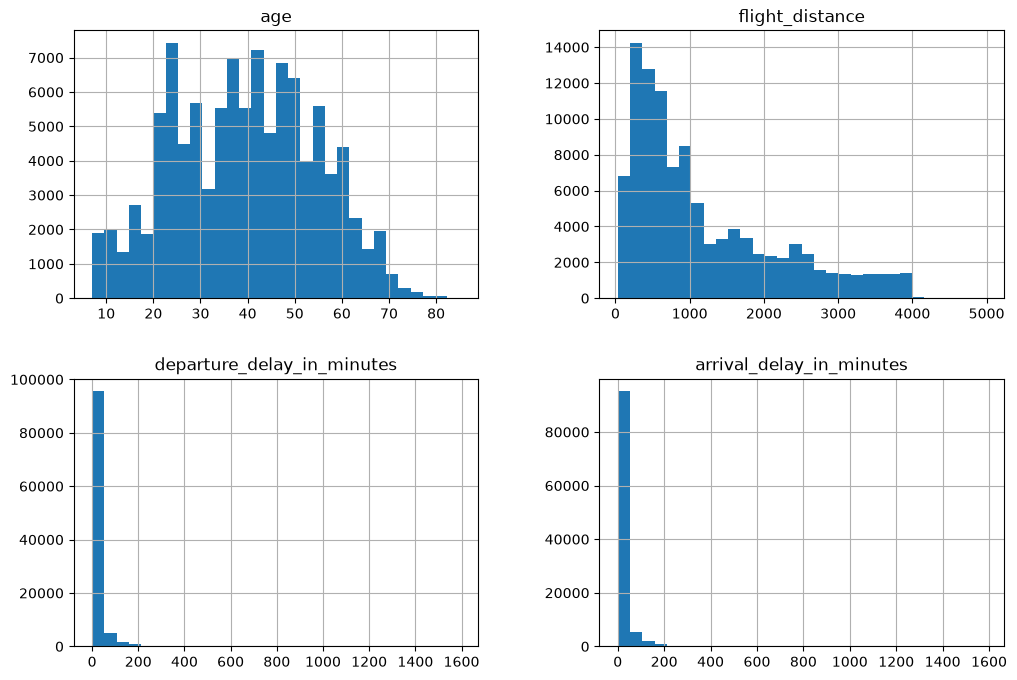

In [19]:
df[['age', 'flight_distance', 'departure_delay_in_minutes', 'arrival_delay_in_minutes']].hist(bins=30, figsize=(12, 8))
plt.show()

Age is roughly bell-shaped. Flight distance is right-skewed but well spread. Both delay columns are heavily right-skewed: most flights are on time, 
and a few have very long delays.The two distributions look almost identical, which matches their 0.96 correlation. 
I kept them as they are, since tree-based models handle skew well, and I may test a log transform for the linear model.

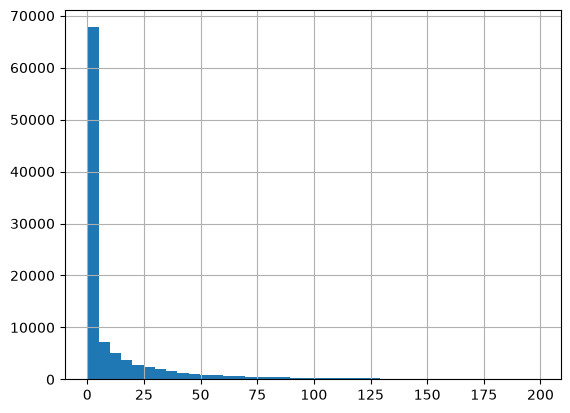

In [20]:
df[df['departure_delay_in_minutes'] < 200]['departure_delay_in_minutes'].hist(bins=40)
plt.show()

In [21]:
df['departure_delay_in_minutes'].quantile([0.5, 0.75, 0.9, 0.99, 1.0])

0.50       0.00
0.75      12.00
0.90      44.00
0.99     181.97
1.00    1592.00
Name: departure_delay_in_minutes, dtype: float64

Both delay columns are heavily right-skewed. The median departure delay is 0 minutes, 90% of flights are delayed 44 minutes or less, and 99% are delayed about 3 hours or less, but the maximum is 1,592 minutes. The two distributions look almost identical, matching their 0.97 correlation. I kept the extreme values, since they are rare, plausible, and tree-based models are not sensitive to them.

In [22]:
df['satisfaction'] = (df['satisfaction'].isin(['satisfied', 1])).astype(int)
df['satisfaction'].value_counts()

satisfaction
0    58879
1    45025
Name: count, dtype: int64

In [23]:
corr_target = df[numerical + ['satisfaction']].corr()['satisfaction'].sort_values(ascending=False)
corr_target

satisfaction                         1.000000
online_boarding                      0.503557
inflight_entertainment               0.398059
seat_comfort                         0.349459
on_board_service                     0.322383
leg_room_service                     0.313131
cleanliness                          0.305198
flight_distance                      0.298780
inflight_wifi_service                0.284245
baggage_handling                     0.247749
inflight_service                     0.244741
checkin_service                      0.236174
food_and_drink                       0.209936
ease_of_online_booking               0.171705
age                                  0.137167
gate_location                        0.000682
departure_delay_in_minutes          -0.050494
departure_arrival_time_convenient   -0.051601
arrival_delay_in_minutes            -0.057522
Name: satisfaction, dtype: float64

Among the numeric features, online boarding (0.50), inflight entertainment (0.40) and seat comfort (0.35) correlate most strongly with satisfaction. Gate location has almost no correlation (0.00), and delays have a weak negative correlation (about -0.05). Together with the categorical analysis, where class and type of travel showed large differences, this suggests which features the models will likely rely on most.

In [24]:
features = [c for c in numerical if c != 'satisfaction']
corr = df[features].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs[pairs > 0.7].sort_values(ascending=False)

departure_delay_in_minutes  arrival_delay_in_minutes    0.965782
inflight_wifi_service       ease_of_online_booking      0.715856
dtype: float64

Based on this result, it shows that only two feature pairs correlate above 0.7 which is departure_delay_in_minutes and arrival_delay_in_minutes that records 0.97. While, inflight_wifi_service and ease_of_online_booking only records 0.72, The delay columns are nearly redundant, so i will test linear model without arrival model. Tree models should not be affected.

In [25]:
from sklearn.model_selection import train_test_split

df_full_train, df_test_internal = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(len(df_train), len(df_val), len(df_test_internal))

62342 20781 20781


In [26]:
y_train = df_train['satisfaction'].values
y_val = df_val['satisfaction'].values
y_test_internal = df_test_internal['satisfaction'].values

df_train = df_train.drop(columns=['satisfaction'])
df_val = df_val.drop(columns=['satisfaction'])
df_test_internal = df_test_internal.drop(columns=['satisfaction'])

In [27]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

C:\Users\nourn\airline-passenger-satisfaction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9274736833002597

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred_rf)

0.9937148740956748

In [30]:
y_pred_train = rf.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred_train)

1.0

In [31]:
for d in [10, 15, 20, None]:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=1, n_jobs=-1)
    m.fit(X_train, y_train)
    y_pred = m.predict_proba(X_val)[:, 1]
    print(d, roc_auc_score(y_val, y_pred))

10 0.9906687240902984
15 0.9932619971365384
20 0.9935670623727779
None 0.9937148740956748


In [32]:
for n in [50, 100, 200, 300]:
    m = RandomForestClassifier(n_estimators=n, max_depth=None, random_state=1, n_jobs=-1)
    m.fit(X_train, y_train)
    y_pred = m.predict_proba(X_val)[:, 1]
    print(n, roc_auc_score(y_val, y_pred))

50 0.9932633600629841
100 0.9937148740956748
200 0.9939098148751108
300 0.9939845972392561


In [33]:
for c in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=c, max_iter=1000)
    m.fit(X_train, y_train)
    y_pred = m.predict_proba(X_val)[:, 1]
    print(c, roc_auc_score(y_val, y_pred))

C:\Users\nourn\airline-passenger-satisfaction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.01 0.9270020355541453


C:\Users\nourn\airline-passenger-satisfaction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.1 0.9273679202080821


C:\Users\nourn\airline-passenger-satisfaction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


1 0.9274736833002597
10 0.9271073756691499


C:\Users\nourn\airline-passenger-satisfaction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [34]:
!pip install xgboost


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=1, n_jobs=-1)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred_xgb)

0.9948645119520191

In [36]:
pd.Series(xgb_model.feature_importances_, index=dv.feature_names_).sort_values(ascending=False).head(10)

online_boarding                    0.380276
type_of_travel=business_travel     0.155384
inflight_wifi_service              0.110670
customer_type=disloyal_customer    0.071601
class=business                     0.051014
inflight_entertainment             0.042982
checkin_service                    0.024853
seat_comfort                       0.019414
baggage_handling                   0.017801
inflight_service                   0.016352
dtype: float32

In [37]:
scores = {}

for d in [3, 5, 7, 10]:
    m = xgb.XGBClassifier(n_estimators=100, max_depth=d, random_state=1, n_jobs=-1)
    m.fit(X_train, y_train)
    y_pred = m.predict_proba(X_val)[:, 1]
    scores[d] = roc_auc_score(y_val, y_pred)
    print(d, scores[d])

3 0.9925044356206184
5 0.9948852378334847
7 0.9949362582800132
10 0.9949144373576447


In [38]:
for lr in [0.05, 0.1, 0.3]:
    m = xgb.XGBClassifier(n_estimators=100, max_depth=7, learning_rate=lr, random_state=1, n_jobs=-1)
    m.fit(X_train, y_train)
    y_pred = m.predict_proba(X_val)[:, 1]
    print(lr, roc_auc_score(y_val, y_pred))

0.05 0.9930835712658259
0.1 0.9947072349399447
0.3 0.9949362582800132


In [39]:
df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train['satisfaction'].values
df_full_train = df_full_train.drop(columns=['satisfaction'])

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(df_full_train.to_dict(orient='records'))
X_test = dv.transform(df_test_internal.to_dict(orient='records'))

final_model = xgb.XGBClassifier(n_estimators=100, max_depth=7, learning_rate=0.3, random_state=1, n_jobs=-1)
final_model.fit(X_full_train, y_full_train)

y_pred_test = final_model.predict_proba(X_test)[:, 1]
roc_auc_score(y_test_internal, y_pred_test)

0.9950312527332253

In [40]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test_internal, final_model.predict(X_test))

0.9624657138732496

In [41]:
df_test = pd.read_csv('data/test.csv')
df_test = df_test.drop(columns=['Unnamed: 0', 'id'])
df_test.columns = df_test.columns.str.lower().str.replace(' ', '_').str.replace('/', '_').str.replace('-', '_')

strings = list(df_test.select_dtypes(include=['object', 'string']).columns)
for col in strings:
    df_test[col] = df_test[col].str.lower().str.replace(' ', '_')

df_test['arrival_delay_in_minutes'] = df_test['arrival_delay_in_minutes'].fillna(df_test['departure_delay_in_minutes'])
df_test['satisfaction'] = (df_test['satisfaction'] == 'satisfied').astype(int)

y_test_final = df_test['satisfaction'].values
X_test_final = dv.transform(df_test.drop(columns=['satisfaction']).to_dict(orient='records'))

roc_auc_score(y_test_final, final_model.predict_proba(X_test_final)[:, 1])

0.995140974667936

In [42]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test_final, final_model.predict(X_test_final))

0.9631967970434246

The final XGBoost model scores 

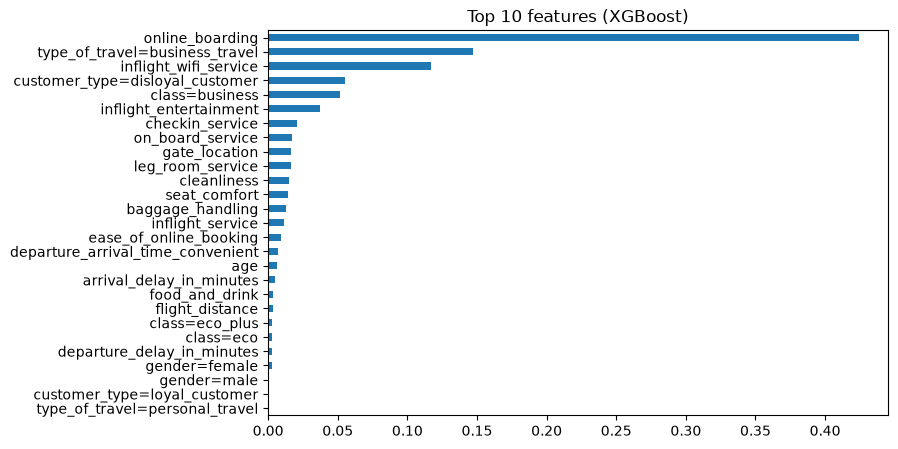

online_boarding                    0.424080
type_of_travel=business_travel     0.146807
inflight_wifi_service              0.117077
customer_type=disloyal_customer    0.055513
class=business                     0.051267
inflight_entertainment             0.036979
checkin_service                    0.020455
on_board_service                   0.017143
gate_location                      0.016311
leg_room_service                   0.016082
dtype: float32

In [46]:
importances = pd.Series(final_model.feature_importances_, index=dv.feature_names_).sort_values(ascending=False)
importances.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Top 10 features (XGBoost)')
plt.savefig('screenshots/feature_importance.png', bbox_inches='tight')
plt.show()

importances.head(10)

## Model comparison

| Model | Validation AUC |
|---|---|
| Logistic regression (default, C=1) | 0.927 |
| Random forest (default, 100 trees) | 0.994 |
| Random forest (tuned: max_depth=None, n_estimators=200) | 0.994 |
| XGBoost (default) | 0.995 |
| XGBoost (tuned: max_depth=7, learning_rate=0.3) | 0.995 |

## Final model scores

| Dataset | AUC |
|---|---|
| Validation | 0.9949 |
| Internal test | 0.9950 |
| test.csv | 0.9951 |